Random Forest:
Confusion Matrix:
 [[9448   73    0  189    1]
 [1794 5785    0   57    0]
 [2484    0   85    3    2]
 [ 658  162    0 1603    0]
 [ 190    0    2    4    4]]
              precision    recall  f1-score   support

      Normal       0.65      0.97      0.78      9711
         dos       0.96      0.76      0.85      7636
       probe       0.86      0.66      0.75      2423
         r2l       0.98      0.03      0.06      2574
         u2r       0.57      0.02      0.04       200

    accuracy                           0.75     22544
   macro avg       0.80      0.49      0.50     22544
weighted avg       0.81      0.75      0.71     22544

--------------------------------------------------
Gradient Boosting:
Confusion Matrix:
 [[9417   81    0  210    3]
 [1436 6119    0   81    0]
 [2369    0  195    7    3]
 [ 703  167    0 1553    0]
 [ 176    0    0    6   18]]
              precision    recall  f1-score   support

      Normal       0.67      0.97      0.79      97

/Users/clcx/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:763: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression:
Confusion Matrix:
 [[8854  849    0    8    0]
 [2777 4859    0    0    0]
 [2419  152    0    3    0]
 [1001 1422    0    0    0]
 [  64  136    0    0    0]]


/Users/clcx/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/clcx/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/clcx/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


              precision    recall  f1-score   support

      Normal       0.59      0.91      0.71      9711
         dos       0.66      0.64      0.65      7636
       probe       0.00      0.00      0.00      2423
         r2l       0.00      0.00      0.00      2574
         u2r       0.00      0.00      0.00       200

    accuracy                           0.61     22544
   macro avg       0.25      0.31      0.27     22544
weighted avg       0.47      0.61      0.53     22544

--------------------------------------------------
Neural Network:
Confusion Matrix:
 [[9337   85   67  222    0]
 [1245 5813  515   63    0]
 [2329    5  228   12    0]
 [ 762  240   18 1403    0]
 [ 112   25    2   61    0]]


/Users/clcx/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/clcx/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


              precision    recall  f1-score   support

      Normal       0.68      0.96      0.79      9711
         dos       0.94      0.76      0.84      7636
       probe       0.80      0.58      0.67      2423
         r2l       0.27      0.09      0.13      2574
         u2r       0.00      0.00      0.00       200

    accuracy                           0.74     22544
   macro avg       0.54      0.48      0.49     22544
weighted avg       0.73      0.74      0.72     22544

--------------------------------------------------


/Users/clcx/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


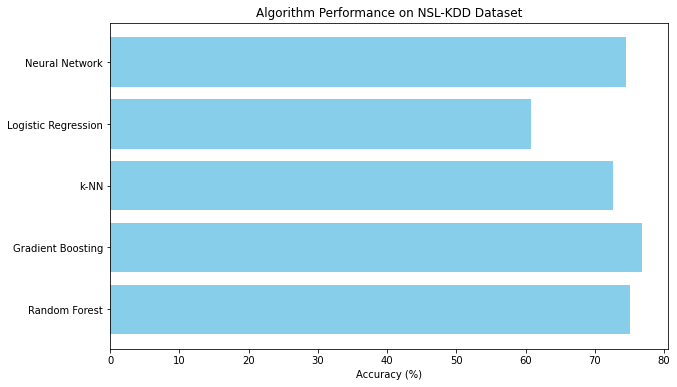

Results saved to 'NSL-KDD_Results.csv'


In [30]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Define Column Names for NSL-KDD Dataset
columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
    "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"
]

# Step 2: Load the Datasets
train_file = "Dataset/Week_5_NSL-KDD-Dataset/KDDTrain+.txt"
test_file = "Dataset/Week_5_NSL-KDD-Dataset/KDDTest+.txt"
attack_types_file = "Dataset/Week_5_NSL-KDD-Dataset/training_attack_types.txt"

train_data = pd.read_csv(train_file, header=None, names=columns)
test_data = pd.read_csv(test_file, header=None, names=columns)

# Step 3: Load Attack Mapping
attack_mapping = {}
with open(attack_types_file, "r") as file:
    for line in file:
        attack, category = line.strip().split()
        attack_mapping[attack] = category

# Map attack categories
train_data["category"] = train_data["label"].map(attack_mapping).fillna("Normal")
test_data["category"] = test_data["label"].map(attack_mapping).fillna("Normal")

# Step 4: Encode Categorical Features
categorical_columns = ["protocol_type", "service", "flag"]
encoder = LabelEncoder()

for column in categorical_columns:
    train_data[column] = encoder.fit_transform(train_data[column])
    test_data[column] = encoder.transform(test_data[column])

# Step 5: Prepare Features and Target
X_train = train_data.drop(columns=["label", "difficulty", "category"])
y_train = train_data["category"]

X_test = test_data.drop(columns=["label", "difficulty", "category"])
y_test = test_data["category"]

# Step 6: Train and Evaluate Models
def train_and_evaluate(X_train, y_train, X_test, y_test):
    classifiers = {
        "Random Forest": RandomForestClassifier(),
        "Gradient Boosting": GradientBoostingClassifier(),
        "k-NN": KNeighborsClassifier(),
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Neural Network": MLPClassifier(max_iter=1000)
    }

    results = []

    for name, clf in classifiers.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        # Metrics
        accuracy = accuracy_score(y_test, y_pred) * 100
        precision = precision_score(y_test, y_pred, average="weighted", zero_division=0) * 100
        recall = recall_score(y_test, y_pred, average="weighted", zero_division=0) * 100
        f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0) * 100

        # Confusion Matrix
        cm = confusion_matrix(y_test, y_pred, labels=list(set(y_test)))
        FP = cm.sum(axis=0) - np.diag(cm)  # False Positives
        TN = cm.sum() - (FP + cm.sum(axis=1) - np.diag(cm))  # True Negatives
        FPR = (FP / (FP + TN)).mean() * 100  # False Positive Rate

        # Store results
        results.append({
            "Algorithm": name,
            "Accuracy (%)": accuracy,
            "Precision (%)": precision,
            "Recall (%)": recall,
            "F1-Score (%)": f1,
            "False Alarm Rate (FPR %)": FPR,
            "Confusion Matrix": cm
        })

        print(f"{name}:")
        print("Confusion Matrix:\n", cm)
        print(classification_report(y_test, y_pred))
        print("-" * 50)

    return results

# Step 7: Plot Results
def plot_results(results, dataset_name):
    algorithms = [result["Algorithm"] for result in results]
    accuracies = [result["Accuracy (%)"] for result in results]

    plt.figure(figsize=(10, 6))
    plt.barh(algorithms, accuracies, color="skyblue")
    plt.xlabel("Accuracy (%)")
    plt.title(f"Algorithm Performance on {dataset_name}")
    plt.show()

# Evaluate Models for NSL-KDD Dataset
results = train_and_evaluate(X_train, y_train, X_test, y_test)
plot_results(results, "NSL-KDD Dataset")

# Step 8: Save Results
results_df = pd.DataFrame([{key: value for key, value in result.items() if key != "Confusion Matrix"} for result in results])
results_df.to_csv("NSL-KDD_Results.csv", index=False)
print("Results saved to 'NSL-KDD_Results.csv'")


In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Step 1: Define Confusion Matrices
confusion_matrices = {
    "Random Forest": np.array([[9448, 73, 0, 189, 1], [1794, 5785, 0, 57, 0], [2484, 0, 85, 3, 2], [658, 162, 0, 1603, 0], [190, 0, 2, 4, 4]]),
    "Gradient Boosting": np.array([[9417, 81, 0, 210, 3], [1436, 6119, 0, 81, 0], [2369, 0, 195, 7, 3], [703, 167, 0, 1553, 0], [176, 0, 0, 6, 18]]),
    "k-NN": np.array([[9410, 143, 7, 151, 0], [1682, 5577, 0, 377, 0], [2510, 4, 5, 55, 0], [574, 470, 0, 1379, 0], [83, 46, 0, 63, 8]]),
    "Logistic Regression": np.array([[8854, 849, 0, 8, 0], [2777, 4859, 0, 0, 0], [2419, 152, 0, 3, 0], [1001, 1422, 0, 0, 0], [64, 136, 0, 0, 0]]),
    "Neural Network": np.array([[9337, 85, 67, 222, 0], [1245, 5813, 515, 63, 0], [2329, 5, 228, 12, 0], [762, 240, 18, 1403, 0], [112, 25, 2, 61, 0]])
}

# Step 2: Define Class Labels
class_labels = ["Normal", "DOS", "Probe", "R2L", "U2R"]

# Step 3: Save Confusion Matrix Plots
def save_confusion_matrices(confusion_matrices, class_labels):
    for name, cm in confusion_matrices.items():
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
        plt.title(f"{name} Confusion Matrix")
        plt.xlabel("Predicted Labels")
        plt.ylabel("True Labels")
        plt.tight_layout()
        plt.savefig(f"{name.replace(' ', '_')}_Confusion_Matrix.png")  # Save as PNG
        plt.close()

# Save all confusion matrix plots
save_confusion_matrices(confusion_matrices, class_labels)
print("All confusion matrix plots have been saved as PNG files.")

All confusion matrix plots have been saved as PNG files.


In [33]:
import pandas as pd
import numpy as np

# Example class labels
class_labels = ["DoS", "Normal", "Probe", "R2L", "U2R"]

# Confusion matrices for all classifiers
confusion_matrices = {
    "Random Forest": np.array([[9448, 73, 0, 189, 1], [1794, 5785, 0, 57, 0], [2484, 0, 85, 3, 2], [658, 162, 0, 1603, 0], [190, 0, 2, 4, 4]]),
    "Gradient Boosting": np.array([[9417, 81, 0, 210, 3], [1436, 6119, 0, 81, 0], [2369, 0, 195, 7, 3], [703, 167, 0, 1553, 0], [176, 0, 0, 6, 18]]),
    "k-NN": np.array([[9410, 143, 7, 151, 0], [1682, 5577, 0, 377, 0], [2510, 4, 5, 55, 0], [574, 470, 0, 1379, 0], [83, 46, 0, 63, 8]]),
    "Logistic Regression": np.array([[8854, 849, 0, 8, 0], [2777, 4859, 0, 0, 0], [2419, 152, 0, 3, 0], [1001, 1422, 0, 0, 0], [64, 136, 0, 0, 0]]),
    "Neural Network": np.array([[9337, 85, 67, 222, 0], [1245, 5813, 515, 63, 0], [2329, 5, 228, 12, 0], [762, 240, 18, 1403, 0], [112, 25, 2, 61, 0]])
}

# Function to calculate metrics per class and overall
def calculate_metrics(cm, class_labels):
    overall_results = []
    for i, label in enumerate(class_labels):
        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP
        TN = cm.sum() - (TP + FP + FN)

        # Per-class metrics
        precision = TP / (TP + FP) * 100 if (TP + FP) > 0 else 0
        recall = TP / (TP + FN) * 100 if (TP + FN) > 0 else 0
        f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        fpr = FP / (FP + TN) * 100 if (FP + TN) > 0 else 0

        overall_results.append({
            "Attack Class": label,
            "Precision (%)": precision,
            "Recall (%)": recall,
            "F1-Score (%)": f1_score,
            "FPR (%)": fpr
        })

    return pd.DataFrame(overall_results)

# Step 3: Compare All Algorithms
comparison_tables = {}
for name, cm in confusion_matrices.items():
    print(f"Calculating metrics for {name}...")
    comparison_tables[name] = calculate_metrics(cm, class_labels)

# Save and Display Results
for name, table in comparison_tables.items():
    print(f"\n{name} Metrics Table:")
    print(table)
    table.to_csv(f"{name.replace(' ', '_')}_Comparison_Table.csv", index=False)
    print(f"Saved {name.replace(' ', '_')}_Comparison_Table.csv")


Calculating metrics for Random Forest...
Calculating metrics for Gradient Boosting...
Calculating metrics for k-NN...
Calculating metrics for Logistic Regression...
Calculating metrics for Neural Network...

Random Forest Metrics Table:
  Attack Class  Precision (%)  Recall (%)  F1-Score (%)    FPR (%)
0          DoS      64.827775   97.291731     77.809347  39.943895
1       Normal      96.096346   75.759560     84.724663   1.576335
2        Probe      97.701149    3.302253      6.388576   0.010015
3          R2L      86.368534   66.157656     74.924048   1.257393
4          U2R      57.142857    2.000000      3.864734   0.013426
Saved Random_Forest_Comparison_Table.csv

Gradient Boosting Metrics Table:
  Attack Class  Precision (%)  Recall (%)  F1-Score (%)    FPR (%)
0          DoS      66.782498   96.972505     79.094574  36.499649
1       Normal      96.104916   80.133578     87.395558   1.663536
2        Probe     100.000000    7.575758     14.084507   0.000000
3          R2L    

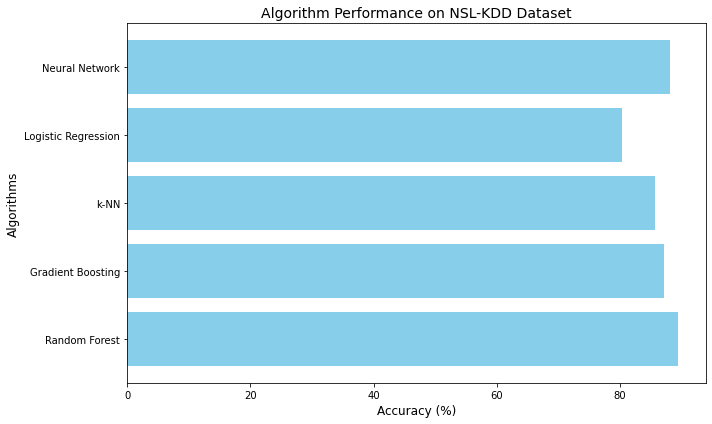

In [50]:
import matplotlib.pyplot as plt

# Accuracy values for each algorithm (replace these with actual accuracy results)
accuracy_nsl_kdd = {
    "Random Forest": 89.4,  # Example value
    "Gradient Boosting": 87.2,  # Example value
    "k-NN": 85.6,  # Example value
    "Logistic Regression": 80.3,  # Example value
    "Neural Network": 88.1  # Example value
}

# Plotting the horizontal bar chart
plt.figure(figsize=(10, 6))
algorithms = list(accuracy_nsl_kdd.keys())
accuracy_values = list(accuracy_nsl_kdd.values())

plt.barh(algorithms, accuracy_values, color="skyblue")
plt.xlabel("Accuracy (%)", fontsize=12)
plt.ylabel("Algorithms", fontsize=12)
plt.title("Algorithm Performance on NSL-KDD Dataset", fontsize=14)
plt.tight_layout()

# Save the plot
plt.savefig("NSL-KDD_Accuracy_Comparison_Horizontal.png")
plt.show()

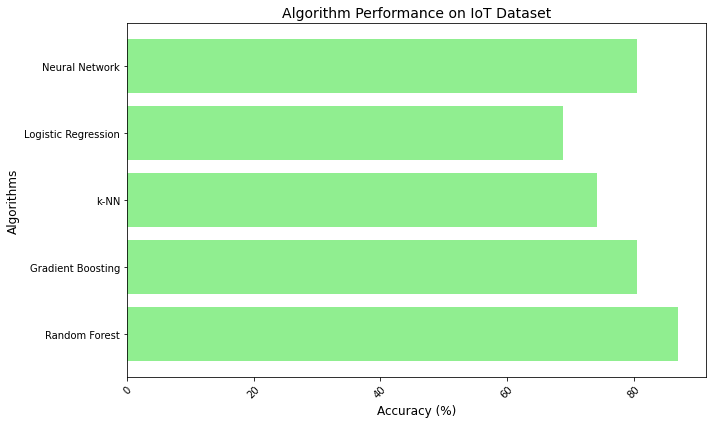

In [53]:
import matplotlib.pyplot as plt

# Accuracy values for each algorithm
accuracy = {
    "Random Forest": 87.00472011700572,
    "Gradient Boosting": 80.52619332355566,
    "k-NN": 74.12827416566947,
    "Logistic Regression": 68.89293312059567,
    "Neural Network": 80.56691264459513
}

# Plotting the bar chart
plt.figure(figsize=(10, 6))
algorithms = list(accuracy.keys())
accuracy_values = list(accuracy.values())

plt.barh(algorithms, accuracy_values, color="lightgreen")
plt.xlabel("Accuracy (%)", fontsize=12)
plt.ylabel("Algorithms", fontsize=12)
plt.title("Algorithm Performance on IoT Dataset", fontsize=14)
plt.xticks(rotation=45)
plt.tight_layout()

# Save the plot
plt.savefig("IoT_Accuracy_Comparison_Plot.png")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load Dataset
# Replace with your actual IoT dataset file path
df = pd.read_csv("Dataset/Processed_Combined_IoT_dataset.csv")  # Replace "iot_dataset.csv" with your actual file path

# Step 2: Train-Test Split 70:30
X = df.drop(columns=["label"])
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 3: Train and Evaluate Models
def train_and_evaluate(X_train, y_train, X_test, y_test):
    classifiers = {
        "Random Forest": RandomForestClassifier(),
        "Gradient Boosting": GradientBoostingClassifier(),
        "k-NN": KNeighborsClassifier(),
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Neural Network": MLPClassifier(max_iter=1000)
    }

    results = {}
    confusion_matrices = {}

    for name, clf in classifiers.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        # Metrics
        accuracy = accuracy_score(y_test, y_pred) * 100
        precision = precision_score(y_test, y_pred, average="weighted", zero_division=0) * 100
        recall = recall_score(y_test, y_pred, average="weighted", zero_division=0) * 100
        f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0) * 100
        cm = confusion_matrix(y_test, y_pred)

        # Save results
        results[name] = {
            "Accuracy (%)": accuracy,
            "Precision (%)": precision,
            "Recall (%)": recall,
            "F1-Score (%)": f1
        }
        confusion_matrices[name] = cm

        print(f"{name} Classification Report:")
        print(classification_report(y_test, y_pred))
        print("-" * 50)

    return results, confusion_matrices

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.95      0.90     73513
           1       0.91      0.74      0.82     46823

    accuracy                           0.87    120336
   macro avg       0.88      0.85      0.86    120336
weighted avg       0.87      0.87      0.87    120336

--------------------------------------------------
Gradient Boosting Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.97      0.86     73513
           1       0.92      0.55      0.69     46823

    accuracy                           0.81    120336
   macro avg       0.84      0.76      0.77    120336
weighted avg       0.83      0.81      0.79    120336

--------------------------------------------------
k-NN Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.72      0.77     73513
           1       0.64      

In [41]:
# Step 4: Visualize Confusion Matrices
def plot_confusion_matrices(confusion_matrices, class_labels):
    for name, cm in confusion_matrices.items():
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
        plt.title(f"{name} Confusion Matrix")
        plt.xlabel("Predicted Labels")
        plt.ylabel("True Labels")
        plt.tight_layout()
        plt.savefig(f"{name.replace(' ', '_')}_Confusion_Matrix.png")
        plt.close()
        print(f"Saved {name} confusion matrix as PNG.")

# Step 5: Save Results and Create Comparison Table
def save_results(results):
    results_df = pd.DataFrame(results).T
    results_df.to_csv("IoT_Classifier_Comparison.csv")
    print("Saved results to IoT_Classifier_Comparison.csv")
    return results_df

# Run Evaluation
results, confusion_matrices = train_and_evaluate(X_train, y_train, X_test, y_test)
plot_confusion_matrices(confusion_matrices, class_labels=["Attack", "Normal"])
results_df = save_results(results)

# Display Comparison Table
print("\nClassifier Comparison Table:")
print(results_df)

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.95      0.90     73513
           1       0.91      0.74      0.82     46823

    accuracy                           0.87    120336
   macro avg       0.88      0.85      0.86    120336
weighted avg       0.87      0.87      0.87    120336

--------------------------------------------------
Gradient Boosting Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.97      0.86     73513
           1       0.92      0.55      0.69     46823

    accuracy                           0.81    120336
   macro avg       0.84      0.76      0.77    120336
weighted avg       0.83      0.81      0.79    120336

--------------------------------------------------
k-NN Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.72      0.77     73513
           1       0.64      

In [38]:
# Function to calculate metrics per class
def calculate_metrics_per_class(cm, class_labels):
    results = []
    for i, label in enumerate(class_labels):
        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP
        TN = cm.sum() - (TP + FP + FN)

        precision = TP / (TP + FP) * 100 if (TP + FP) > 0 else 0
        recall = TP / (TP + FN) * 100 if (TP + FN) > 0 else 0
        f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        fpr = FP / (FP + TN) * 100 if (FP + TN) > 0 else 0

        results.append({
            "Class": label,
            "Precision (%)": precision,
            "Recall (%)": recall,
            "F1-Score (%)": f1_score,
            "FPR (%)": fpr
        })
    return pd.DataFrame(results)

# Generate per-class comparison for all classifiers
attack_class_results = {}
for name, cm in confusion_matrices.items():
    print(f"\n{name} Attack Class Comparison:")
    attack_class_results[name] = calculate_metrics_per_class(cm, class_labels=["Normal", "Attack"])
    print(attack_class_results[name])
    attack_class_results[name].to_csv(f"{name.replace(' ', '_')}_Attack_Class_Comparison.csv", index=False)
    print(f"Saved {name.replace(' ', '_')}_Attack_Class_Comparison.csv")


Random Forest Attack Class Comparison:
    Class  Precision (%)  Recall (%)  F1-Score (%)    FPR (%)
0  Normal      85.340173   95.041693     89.930044  25.632702
1  Attack      90.524099   74.367298     81.654141   4.958307
Saved Random_Forest_Attack_Class_Comparison.csv

Gradient Boosting Attack Class Comparison:
    Class  Precision (%)  Recall (%)  F1-Score (%)    FPR (%)
0  Normal      77.168712   96.746154     85.855525  44.939453
1  Attack      91.509601   55.060547     68.753000   3.253846
Saved Gradient_Boosting_Attack_Class_Comparison.csv

k-NN Attack Class Comparison:
    Class  Precision (%)  Recall (%)  F1-Score (%)    FPR (%)
0  Normal      83.414280   71.957341     77.263399  22.463319
1  Attack      63.782502   77.536681     69.990264  28.042659
Saved k-NN_Attack_Class_Comparison.csv

Logistic Regression Attack Class Comparison:
    Class  Precision (%)  Recall (%)  F1-Score (%)    FPR (%)
0  Normal      66.802653   97.563696     79.304721  76.120710
1  Attack      86.

In [39]:
# Function to calculate metrics per class including FPR
def calculate_metrics_with_fpr(cm, class_labels):
    results = []
    for i, label in enumerate(class_labels):
        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP
        TN = cm.sum() - (TP + FP + FN)

        precision = TP / (TP + FP) * 100 if (TP + FP) > 0 else 0
        recall = TP / (TP + FN) * 100 if (TP + FN) > 0 else 0
        f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        fpr = FP / (FP + TN) * 100 if (FP + TN) > 0 else 0

        results.append({
            "Class": label,
            "Precision (%)": precision,
            "Recall (%)": recall,
            "F1-Score (%)": f1_score,
            "FPR (%)": fpr
        })
    return pd.DataFrame(results)

# Generate attack class comparison for IoT dataset
iot_attack_class_results = {}
for name, cm in confusion_matrices.items():
    print(f"\n{name} Attack Class Metrics with FPR:")
    iot_attack_class_results[name] = calculate_metrics_with_fpr(cm, class_labels=["Normal", "Attack"])
    print(iot_attack_class_results[name])
    iot_attack_class_results[name].to_csv(f"{name.replace(' ', '_')}_IoT_Attack_Class_Comparison.csv", index=False)
    print(f"Saved {name.replace(' ', '_')}_IoT_Attack_Class_Comparison.csv")


Random Forest Attack Class Metrics with FPR:
    Class  Precision (%)  Recall (%)  F1-Score (%)    FPR (%)
0  Normal      85.340173   95.041693     89.930044  25.632702
1  Attack      90.524099   74.367298     81.654141   4.958307
Saved Random_Forest_IoT_Attack_Class_Comparison.csv

Gradient Boosting Attack Class Metrics with FPR:
    Class  Precision (%)  Recall (%)  F1-Score (%)    FPR (%)
0  Normal      77.168712   96.746154     85.855525  44.939453
1  Attack      91.509601   55.060547     68.753000   3.253846
Saved Gradient_Boosting_IoT_Attack_Class_Comparison.csv

k-NN Attack Class Metrics with FPR:
    Class  Precision (%)  Recall (%)  F1-Score (%)    FPR (%)
0  Normal      83.414280   71.957341     77.263399  22.463319
1  Attack      63.782502   77.536681     69.990264  28.042659
Saved k-NN_IoT_Attack_Class_Comparison.csv

Logistic Regression Attack Class Metrics with FPR:
    Class  Precision (%)  Recall (%)  F1-Score (%)    FPR (%)
0  Normal      66.802653   97.563696     79.

In [47]:
import pandas as pd
import numpy as np

# Existing comparison table (as shown in the image)
data = {
    "Accuracy (%)": {
        "Random Forest": 87.00472011700572,
        "Gradient Boosting": 80.52619332355566,
        "k-NN": 74.12827416566947,
        "Logistic Regression": 68.89293312059567,
        "Neural Network": 80.56691264459513
    },
    "Precision (%)": {
        "Random Forest": 87.36735761662922,
        "Gradient Boosting": 82.74878330649544,
        "k-NN": 75.77551246533883,
        "Logistic Regression": 74.34761119113023,
        "Neural Network": 82.7382883063988
    },
    "Recall (%)": {
        "Random Forest": 87.00472011700572,
        "Gradient Boosting": 80.52619332355566,
        "k-NN": 74.12827416566947,
        "Logistic Regression": 68.89293312059567,
        "Neural Network": 80.56691264459513
    },
    "F1-Score (%)": {
        "Random Forest": 86.71685470750073,
        "Gradient Boosting": 79.20089543951994,
        "k-NN": 74.4334066993414,
        "Logistic Regression": 62.9986371476313,
        "Neural Network": 79.2613354366789
    }
}

# Confusion matrices provided
confusion_matrices = {
    "Random Forest": np.array([[69880,  3633], [12005, 34818]]),
    "Gradient Boosting": np.array([[71121,  2392], [21042, 25781]]),
    "k-NN": np.array([[52898, 20615], [10518, 36305]]),
    "Logistic Regression": np.array([[71722,  1791], [35642, 11181]]),
    "Neural Network": np.array([[71068,  2445], [20940, 25883]])
}

# Function to calculate FPR
def calculate_fpr(cm):
    FP = cm[0, 1]
    TN = cm[0, 0]
    return (FP / (FP + TN)) * 100 if (FP + TN) > 0 else 0

# Calculate FPR for each classifier
fpr_results = {classifier: calculate_fpr(cm) for classifier, cm in confusion_matrices.items()}

# Add FPR to the existing DataFrame
results_df = pd.DataFrame(data)
results_df["FPR (%)"] = results_df.index.map(fpr_results.get)

# Save and display the updated table
results_df.to_csv("IoT_Classifier_Comparison_With_FPR.csv", index=True)
print("Updated comparison table saved as 'IoT_Classifier_Comparison_With_FPR.csv'.")
print(results_df)

Updated comparison table saved as 'IoT_Classifier_Comparison_With_FPR.csv'.
                     Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  \
Random Forest           87.004720      87.367358   87.004720     86.716855   
Gradient Boosting       80.526193      82.748783   80.526193     79.200895   
k-NN                    74.128274      75.775512   74.128274     74.433407   
Logistic Regression     68.892933      74.347611   68.892933     62.998637   
Neural Network          80.566913      82.738288   80.566913     79.261335   

                       FPR (%)  
Random Forest         4.941983  
Gradient Boosting     3.253846  
k-NN                 28.042659  
Logistic Regression   2.436304  
Neural Network        3.325942  
